Aditya Dhruv.  Job & Resume Matching Dataset, Version 1. Retrieved 11/16/2025 from https://www.kaggle.com/datasets/adityadhruv/job-and-resume-matching-dataset?resource=download&select=resume.xlsx

The file has been updated in the following ways:
1. Saved as a CSV file for easy manipulation and compatiblity
2. For assignment purposes, artificial job acceptance labels have been randomly assigned to the resume entries
3. Removed nonsensical columns (cover letter, LinkedIn profile link, Github profile link, volunteer experience, certifications)

In [1]:
import pandas as pd
resume_raw = pd.read_csv('Resume_Data(V11.30.0244).csv')
resume_raw.head()

,first_name,last_name,age,email,country,education_level,skills,experience_years,current_job_title,languages_spoken,technical_proficiencies,references_available,availability_date,github_contributions,previous title level,professional level,additional_training,job_accepted
0,Noell,Yurshev,49,nyurshevmn@cnn.com,China,Technical Degree,video editing,30,Structural Analysis Engineer,Italian,Angular,True,6/6/2022,894,Web Developer I,mid,customer service,1
1,Bogey,Crittal,30,bcrittal3z@bigcartel.com,China,Trade School Certificate,public speaking,30,Cost Accountant,Swedish,CSS,True,9/4/2022,851,Recruiting Manager,mid,team building,1
2,Blinnie,Henric,76,bhenricaf@merriam-webster.com,China,Professional Certification,marketing,30,Clinical Specialist,Dutch,Kubernetes,False,11/8/2023,766,Structural Engineer,lead,team building,1
3,Gerty,Harrap,83,gharrap2m@prnewswire.com,Brazil,Technical Degree,photography,30,Associate Professor,Greek,Jenkins,True,1/14/2022,762,Recruiter,senior,time management,0
4,Albrecht,Braidwood,75,abraidwoodct@printfriendly.com,China,PhD,public relations,30,Staff Accountant IV,Tagalog,Angular,False,10/20/2023,751,Community Outreach Specialist,lead,problem solving,1


Clean the data.

In [2]:
#Check the number of entries, attributes, and data types for the attributes
resume_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   first_name               1000 non-null   object
 1   last_name                1000 non-null   object
 2   age                      1000 non-null   int64 
 3   email                    1000 non-null   object
 4   country                  1000 non-null   object
 5   education_level          1000 non-null   object
 6   skills                   1000 non-null   object
 7   experience_years         1000 non-null   int64 
 8   current_job_title        1000 non-null   object
 9   languages_spoken         1000 non-null   object
 10  technical_proficiencies  1000 non-null   object
 11  references_available     1000 non-null   bool  
 12  availability_date        1000 non-null   object
 13  github_contributions     1000 non-null   int64 
 14  previous title level     1000 non-null   

In [3]:
#Get statistical information for the ages
print(resume_raw['age'].describe())
#No ages appear to be outliers


#If years of experience > age, remove the entire entry
print("Initial entries: ")
print(len(resume_raw)) #How many initial entries before applying rule
resume_raw['exp_vs_age'] = resume_raw['experience_years'] > resume_raw['age'] #Create column checking if experience > age
resume_raw = resume_raw[resume_raw['exp_vs_age'] == False] #Remove all entries where age < experience
resume_raw.head()
print("Remove experience > age:" )
print(len(resume_raw)) #Check how many entries after applying rule

#If people started working before age 16, remove the entire entry
resume_raw['child_labor'] = resume_raw['age'] - resume_raw['experience_years'] < 16 #Create column checking if difference between age and experience < 16
resume_raw = resume_raw[resume_raw['child_labor'] == False] #Remove all entries where delta age-experience < 16
resume_raw.head()
print("Remove working before 16:" )
print(len(resume_raw)) #Check how many entries after applying rule

#If people have a negative age or a negative years of experience, remove the entire entry
resume_raw['negative_age'] = resume_raw['age'] < 0 #Create column checking for negative age
resume_raw['negative_exp'] = resume_raw['experience_years'] < 0 #Create column checking for negative years of experience
#Remove all columns that don't pass rules
resume_raw = resume_raw[resume_raw['negative_age'] == False]
resume_raw = resume_raw[resume_raw['negative_exp'] == False]
resume_raw.head()
print("Remove negative age and negative experience: ")
print(len(resume_raw)) #Check how many entries after applying rules


count    1000.000000
mean       51.389000
std        19.325453
min        18.000000
25%        34.000000
50%        52.000000
75%        68.000000
max        85.000000
Name: age, dtype: float64
Initial entries: 
1000
Remove experience > age:
965
Remove working before 16:
818
Remove negative age and negative experience: 
818


In [4]:
resume_f = resume_raw
#After first round of cleaning, convert to new object for further cleaning

In [5]:
#Remove whitespace and convert all text to lowercase
text_columns = ['first_name', 'last_name', 'email', 'country', 'education_level',
                'skills', 'current_job_title', 'languages_spoken', 'technical_proficiencies',
                'previous title level', 'professional level', 'additional_training']

for c in text_columns:
  resume_f[c] = resume_f[c].astype(str).str.strip().str.lower() #Make sure all are string type, strip whitespace, convert to lowercase

resume_f.head() #Show a few lines to check if it worked

,first_name,last_name,age,email,country,education_level,skills,experience_years,current_job_title,languages_spoken,...,availability_date,github_contributions,previous title level,professional level,additional_training,job_accepted,exp_vs_age,child_labor,negative_age,negative_exp
0,noell,yurshev,49,nyurshevmn@cnn.com,china,technical degree,video editing,30,structural analysis engineer,italian,...,6/6/2022,894,web developer i,mid,customer service,1,False,False,False,False
2,blinnie,henric,76,bhenricaf@merriam-webster.com,china,professional certification,marketing,30,clinical specialist,dutch,...,11/8/2023,766,structural engineer,lead,team building,1,False,False,False,False
3,gerty,harrap,83,gharrap2m@prnewswire.com,brazil,technical degree,photography,30,associate professor,greek,...,1/14/2022,762,recruiter,senior,time management,0,False,False,False,False
4,albrecht,braidwood,75,abraidwoodct@printfriendly.com,china,phd,public relations,30,staff accountant iv,tagalog,...,10/20/2023,751,community outreach specialist,lead,problem solving,1,False,False,False,False
5,adolf,kloser,50,akloser17@ezinearticles.com,myanmar,associate's degree,problem solving,30,social worker,hindi,...,2/3/2023,690,account representative i,senior,creative thinking,1,False,False,False,False


In [6]:
print("Number of entries:", len(resume_f)) #Check how many current entries
print(resume_f.isna().sum()) #Print how many null values by attribute
resume_f = resume_f.dropna() #Remove any entries which contain null values
print("Number of entries, Null values removed: ", len(resume_f)) #Check how many entries after removing entries containing null values

Number of entries: 818
first_name                 0
last_name                  0
age                        0
email                      0
country                    0
education_level            0
skills                     0
experience_years           0
current_job_title          0
languages_spoken           0
technical_proficiencies    0
references_available       0
availability_date          0
github_contributions       0
previous title level       0
professional level         0
additional_training        0
job_accepted               0
exp_vs_age                 0
child_labor                0
negative_age               0
negative_exp               0
dtype: int64
Number of entries, Null values removed:  818


In [7]:
print(resume_f['github_contributions'].describe())
#Print statistical information of Github Contribution attribute.
# No Github contributions by pure numbers appear to be outliers.
print("Number of entries: ", len(resume_f)) #Check how many current entries

#LOGIC CHECK
#GitHub contribution rules: To have a high number of contributions, must have sufficient experience or relevant degree.
#If GH > 400, must have >= 2 years of experience OR Master's/PHD
#If GH > 700, must have >= 4 years of experience OR Master's/PHD

def github_rule(r): #Github rule function with dataset as argument
  gh = r['github_contributions'] #Set gh variable to the github contributions column of the dataset
  exp = r['experience_years'] #Set exp variable to the experience_years column of the dataset
  edu = r['education_level'] #Set edu variable to the education level column of the dataset

  if gh > 400:
    if exp >= 2 or edu in ["master's degree", "phd"]:
      return True
    else:
      return False

  elif gh > 700:
    if exp >= 4 or edu in ["master's degree", "phd"]:
      return True
    else:
      return False

  else:
    return True


resume_f['github_rule'] = resume_f.apply(github_rule, axis = 1) #Apply github rule function across all entries in the resume dataset
resume_f = resume_f[resume_f['github_rule'] == True] #Remove all entries that don't pass github rule
print(resume_f['github_contributions'].describe()) #Print statistical description to see changes after performing a logic check

print("Number of entries, Github rule applied: ", len(resume_f)) #Check how many current entries after applying rule
resume_f.head()

count    818.000000
mean     506.244499
std      284.862390
min        2.000000
25%      268.250000
50%      502.000000
75%      753.750000
max      999.000000
Name: github_contributions, dtype: float64
Number of entries:  818
count    787.000000
mean     500.381194
std      287.354706
min        2.000000
25%      257.500000
50%      492.000000
75%      752.000000
max      999.000000
Name: github_contributions, dtype: float64
Number of entries, Github rule applied:  787


,first_name,last_name,age,email,country,education_level,skills,experience_years,current_job_title,languages_spoken,...,github_contributions,previous title level,professional level,additional_training,job_accepted,exp_vs_age,child_labor,negative_age,negative_exp,github_rule
0,noell,yurshev,49,nyurshevmn@cnn.com,china,technical degree,video editing,30,structural analysis engineer,italian,...,894,web developer i,mid,customer service,1,False,False,False,False,True
2,blinnie,henric,76,bhenricaf@merriam-webster.com,china,professional certification,marketing,30,clinical specialist,dutch,...,766,structural engineer,lead,team building,1,False,False,False,False,True
3,gerty,harrap,83,gharrap2m@prnewswire.com,brazil,technical degree,photography,30,associate professor,greek,...,762,recruiter,senior,time management,0,False,False,False,False,True
4,albrecht,braidwood,75,abraidwoodct@printfriendly.com,china,phd,public relations,30,staff accountant iv,tagalog,...,751,community outreach specialist,lead,problem solving,1,False,False,False,False,True
5,adolf,kloser,50,akloser17@ezinearticles.com,myanmar,associate's degree,problem solving,30,social worker,hindi,...,690,account representative i,senior,creative thinking,1,False,False,False,False,True


In [8]:
#Check age against professional level

print(resume_f['professional level'].unique()) #Check the different values for professional level represented in dataset
print("Number of entries: ", len(resume_f)) #Check how many current entries

#LOGIC CHECK
#Junior: minimum age 18
#Mid: minimum age 25
#Senior: minimum age 30
#Lead: minimum age 32
#Executive: minimum age 40

['mid' 'lead' 'senior' 'executive' 'junior']
Number of entries:  787


In [9]:
#Create dictionary matching professional level to minimum age as determined above
#Determined using basic logic checks and industry trends

min_age_by_level = {
    'junior': 18,
    'mid': 25,
    'senior': 30,
    'lead': 32,
    'executive': 40,
}

def age_vs_level(r): #Age/professional level function with dataset as argument
  age = r['age'] #Set age variable to the age column of the dataset
  level = r['professional level'] #Set level variable to the professional level column of the dataset

  if age < min_age_by_level[level]: #If age in the current entry of the dataset is less than the matched age in the dictionary for the level in the entry, do not pass test
    return False
  else:
    return True

resume_f['age_vs_level'] = resume_f.apply(age_vs_level, axis = 1) #Apply age/professional level rule to the resume dataset
resume_f = resume_f[resume_f['age_vs_level'] == True] #Remove entries that do not pass rule

print("Number of entries, Professional level rule applied: ", len(resume_f)) #Check how many entries after applying age/professional level rule

Number of entries, Professional level rule applied:  742


In [10]:
#Check experience against professional level

print(resume_f['professional level'].unique()) #Check the different values for professional level represented in dataset
print("Number of entries: ", len(resume_f)) #Check how many current entries

#LOGIC CHECK
#Junior: minimum 0 experience
#Mid: minimum 2 experience
#Senior: minimum 5 experience
#Lead: minimum 8 experience
#Executive: minimum 12 experience

['mid' 'lead' 'senior' 'executive' 'junior']
Number of entries:  742


In [11]:
#Create dictionary matching professional level to minimum years of experience as determined above
#Determined using basic logic checks and industry trends

min_exp_by_level = {
    'junior': 0,
    'mid': 2,
    'senior': 5,
    'lead': 8,
    'executive': 12,
}

def exp_vs_level(r): #Experience/professional level function with dataset as argument
  exp = r['experience_years'] #Set exp variable to the experience_years column of the dataset
  level = r['professional level'] #Set level variable to the professional level column of the dataset

  if exp < min_exp_by_level[level]: #If experience in the current entry of the dataset is less than the matched experience in the dictionary for the level in the entry, do not pass test
    return False
  else:
    return True

resume_f['exp_vs_level'] = resume_f.apply(exp_vs_level, axis = 1) #Apply experience/professional level rule to the resume dataset
resume_f = resume_f[resume_f['exp_vs_level'] == True] #Remove entries that do not pass rule

print("Number of entries, Professional level/Experience rule applied: ", len(resume_f)) #Check how many entries after applying professional level/experience rule

Number of entries, Professional level/Experience rule applied:  644


In [12]:
print(resume_f['education_level'].unique()) #Check the different values for educational level represented in dataset

['technical degree' 'professional certification' 'phd'
 "associate's degree" "master's degree" "bachelor's degree" 'no degree'
 'trade school certificate' 'some college' 'ged' 'high school diploma']


In [13]:
#Check age against degree
print("Number of entries:", len(resume_f)) #Check how many current entries

#Create dictionary matching professional level to minimum age as determined below
#Determined using basic logic checks and industry trends
min_age_by_edu = {
    "associate's degree": 19,
    "bachelor's degree": 21,
    "master's degree": 23,
    "phd": 26,
    "technical degree": 18,
    "professional certification": 18,
    "no degree": 18,
    "trade school certificate": 19,
    "some college": 18,
    "high school diploma": 17,
    "ged": 17
}

def edu_vs_age(r): #Education/age function with dataset as argument
    age = r['age'] #Set age variable to the age column of the dataset
    edu = r['education_level'] #Set edu variable to the education_level column of the dataset

    if age < min_age_by_edu[edu]: #If age in the current entry of the dataset is less than the matched age in the dictionary for the education in the entry, do not pass test
        return False
    else:
        return True

resume_f['age_vs_edu'] = resume_f.apply(edu_vs_age, axis = 1) #Apply age/education level rule to the resume dataset
resume_f = resume_f[resume_f['age_vs_edu'] == True] #Remove entries that do not pass test

print("Number of entries, Educational level rule applied: ", len(resume_f)) #Check how many entries after applying age/educational level rule


Number of entries: 644
Number of entries, Educational level rule applied:  644


Additional rule ideas:
Remove unlikely combo / "underperformer"
If 15+ years of experience & bachelor's/master's/phd AND NOT lead/executive, remove
If 75+ years old, remove (retirement)

In [14]:
resume_f = resume_f.drop_duplicates()
print(len(resume_f))
#The function to drop exact duplicates has been run, and the number of entries before and after running has been checked. No duplicates existed.

#This version of the resume dataset is what we are now working with for EDA.

644


Perform Exploratory Data Analysis.

In [15]:
import matplotlib.pyplot as plt
import numpy as np

[15 25 35 45 55 65 75 85]


Text(0, 0.5, 'Frequency')

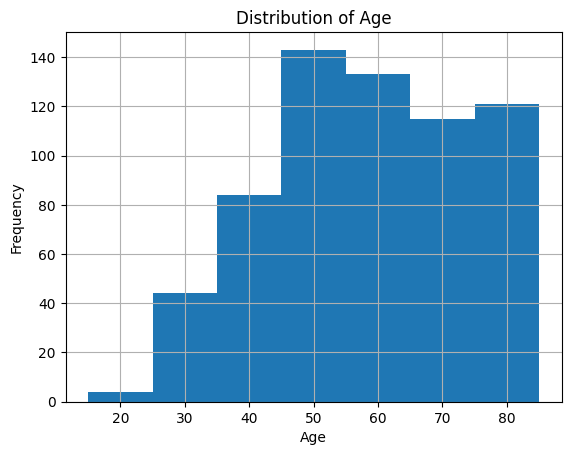

In [16]:
#Visualize the distribution of age
bin_range = np.arange(15, 95, 10) #Create bins of 10 year age ranges 15-75
print(bin_range) #Show the bin boundaries
resume_f['age'].hist(bins = bin_range) #Generate histogram
#Add labels
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

count    644.000000
mean      17.013975
std        7.924103
min        0.000000
25%       11.000000
50%       17.000000
75%       24.000000
max       30.000000
Name: experience_years, dtype: float64
[ 0  5 10 15 20 25 30]


Text(0, 0.5, 'Frequency')

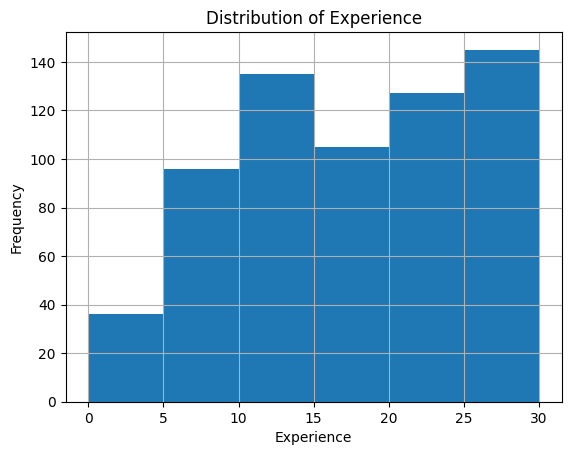

In [17]:
#Visualize the distribution of experience
print(resume_f['experience_years'].describe())
bin_exp = np.arange(0, 31, 5) #Create bins of 5 year ranges for experience 0 to 30
print(bin_exp) #Show the bin boundaries
resume_f['experience_years'].hist(bins = bin_exp) #Generate histogram of experience frequency
#Add labels
plt.title("Distribution of Experience")
plt.xlabel("Experience")
plt.ylabel("Frequency")

Citation: https://www.geeksforgeeks.org/python/python-pearson-correlation-test-between-two-variables/

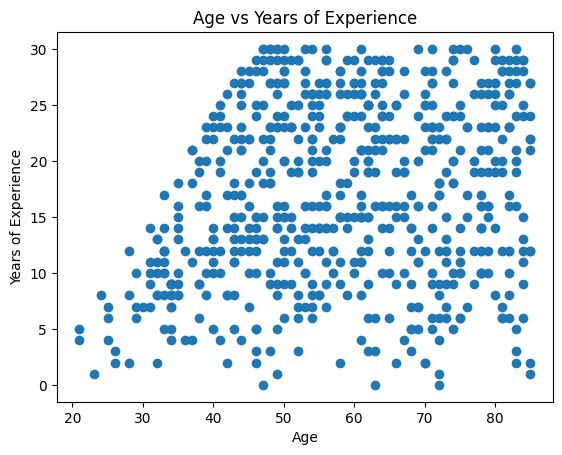

Pearson Correlation Coefficient: 0.215
P-Value: 0.00000004


In [18]:
import numpy as np
#Scatter plot of plotting age against years of experience
plt.scatter(resume_f['age'], resume_f['experience_years'])
#Add labels
plt.title("Age vs Years of Experience")
plt.xlabel("Age")
plt.ylabel("Years of Experience")
plt.show()

from scipy.stats import pearsonr
#Generate correlation coefficient and p-value for plotting age against experience
correlation_a, p_value_a = pearsonr(resume_f['age'], resume_f['experience_years'])
print(f"Pearson Correlation Coefficient: {correlation_a:.3f}")
print(f"P-Value: {p_value_a:.8f}")

#INTERPRETATION
#Weak positive correlation - as age increases, years of experience increase (expected positive, but expected stronger correlation)
#Very small p-value (<0.05) - statistically significant relationship
#Note: If pre-processing had not been performed, likely would have seen either a weaker correlation or a non-statistically significant relationship

Citation: https://www.geeksforgeeks.org/data-science/spearmans-rank-correlation/

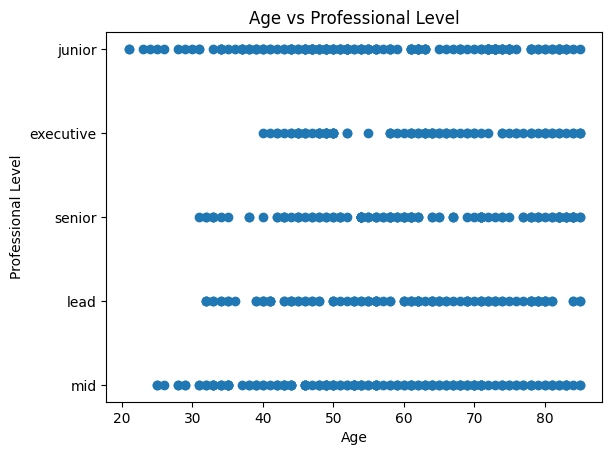

Spearman Correlation Coefficient: 0.117
P-Value: 0.00285824


In [19]:
#Plot age against professional level
#Convert professional level (categorical, ordered variable) to a number for easier statistical testing

#Create dictionary/map for professional level
level_map = {
    'junior': 1,
    'mid': 2,
    'senior': 3,
    'lead': 4,
    'executive': 5
}

resume_f['level_rank'] = resume_f['professional level'].map(level_map) #Create new column using level mapping defined above

plt.scatter(resume_f['age'], resume_f['professional level']) #Plot age vs professional level with text labels
#Add labels
plt.title("Age vs Professional Level")
plt.xlabel("Age")
plt.ylabel("Professional Level")
plt.show()

#Check correlation and statistical significance using spearman test
#Spearman test useful for checking continuous var (age) against ordinal var (level)
from scipy.stats import spearmanr

correlation_s, p_value_s = spearmanr(resume_f['age'], resume_f['level_rank'])

print(f"Spearman Correlation Coefficient: {correlation_s:.3f}")
print(f"P-Value: {p_value_s:.8f}")

#INTERPRETATION
#Weak correlation coefficient clsoe to 0 - no relationship between age and professional level (matches visualization)
#Unexpected with real-life data but knowing this is artifical data, is logical
#p-value < 0.05 - statistically significant results

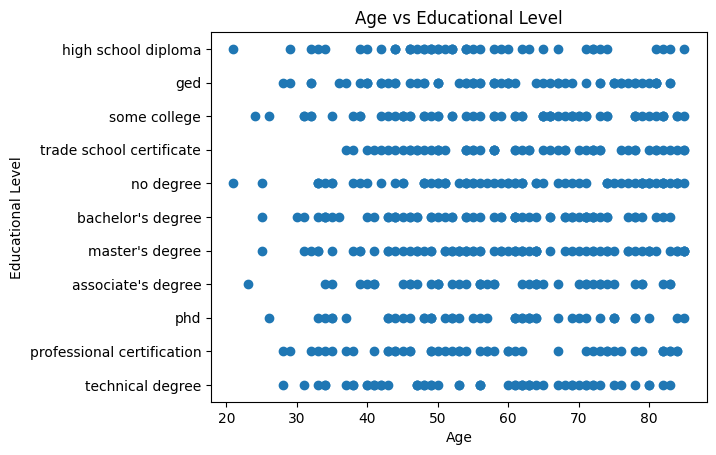

Spearman Correlation Coefficient: -0.023
P-Value: 0.55231495


In [20]:
#Plot age against educational level
#Convert educational level (categorical, ordered variable) to a number for easier statistical testing

#Create dictionary/map for educational level
edu_map = {
    "associate's degree": 7,
    "bachelor's degree": 8,
    "master's degree": 9,
    "phd": 10,
    "technical degree": 6,
    "professional certification": 5,
    "no degree": 0,
    "trade school certificate": 3,
    "some college": 4,
    "high school diploma": 2,
    "ged": 1
}

resume_f['edu_rank'] = resume_f['education_level'].map(edu_map) #Create new column using education mapping defined above

plt.scatter(resume_f['age'], resume_f['education_level']) #Plot age vs education level with text labels
#Add labels
plt.title("Age vs Educational Level")
plt.xlabel("Age")
plt.ylabel("Educational Level")
plt.show()

#Check correlation and statistical significance using spearman test
#Spearman test useful for checking continuous var (age) against ordinal var (education)

correlation_se, p_value_se = spearmanr(resume_f['age'], resume_f['edu_rank'])

print(f"Spearman Correlation Coefficient: {correlation_se:.3f}")
print(f"P-Value: {p_value_se:.8f}")

#INTERPRETATION
#Weak correlation coefficient clsoe to 0 - essentially relationship between age and peducational level (matches visualization)
#Unexpected with real-life data but knowing this is artifical data, is logical
#p-value > 0.05 - not a statistically significant result; cannot draw that this is an actual conclusion, could be due to chance

Citation: https://www.geeksforgeeks.org/python/how-to-create-a-seaborn-correlation-heatmap-in-python/

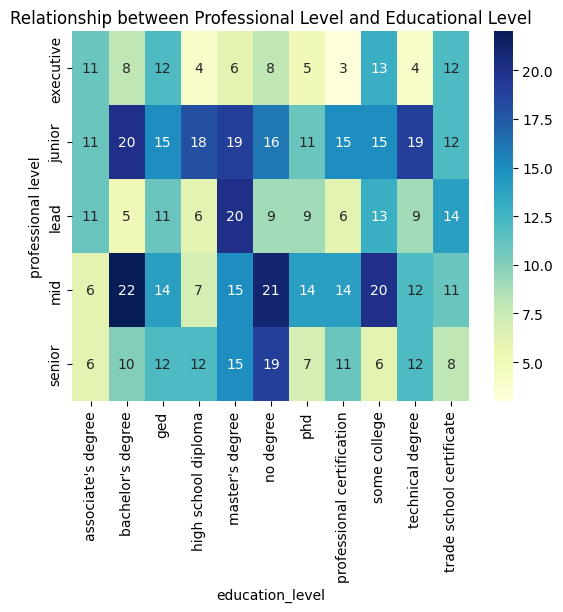

Spearman Correlation Coefficient: -0.024
P-Value: 0.53790286


In [21]:
#Plot educational level against professional level with heatmap

contingency_tab = pd.crosstab(
    index = resume_f['professional level'], #each professional level = row
    columns = resume_f['education_level'] #each educational level = column
)

import seaborn as sns #Import necessary capability

sns.heatmap(contingency_tab, annot = True, fmt = 'd', cmap = 'YlGnBu')
#Create heatmap from contingency_tab, annotated with numerical values in decimal integers, with Yellow/Green/Blue color scheme
#Add labels
plt.title("Relationship between Professional Level and Educational Level")
plt.show()

# spearman also useful for ordinal vs ordinal
correlation_pe, p_value_pe = spearmanr(resume_f['level_rank'], resume_f['edu_rank'])

print(f"Spearman Correlation Coefficient: {correlation_pe:.3f}")
print(f"P-Value: {p_value_pe:.8f}")

#INTERPRETATION
#Weak correlation coefficient clsoe to 0 - no relationship between professional level and educational level (matches visualization)
#Unexpected with real-life data but knowing this is artifical data, is logical
#p-value > 0.05 - not a statistically significant result; cannot draw that this is an actual conclusion, could be due to chance

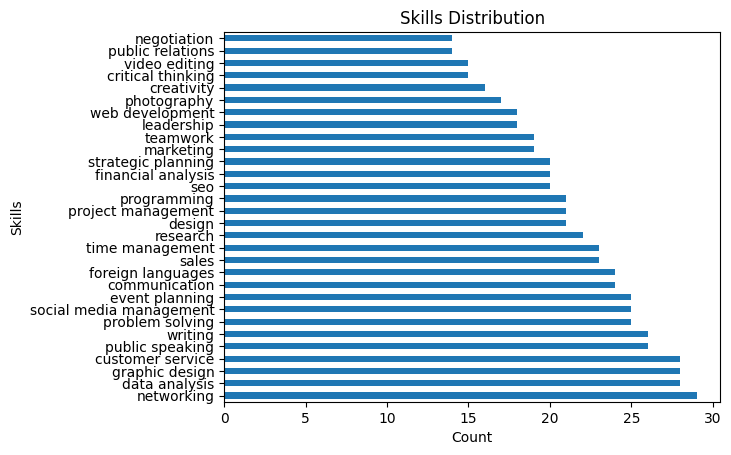

In [22]:
#Plot skills distribution (frequency)
resume_f['skills'].value_counts().plot(kind='barh')
#Add labels
plt.title("Skills Distribution")
plt.xlabel("Count")
plt.ylabel("Skills")
plt.show()

professional level  skills            
executive           networking             6
                    project management     6
                    event planning         5
junior              graphic design        11
                    time management       10
                    communication          9
lead                financial analysis     9
                    customer service       6
                    data analysis          6
mid                 foreign languages     10
                    public speaking        9
                    data analysis          8
senior              writing                8
                    event planning         7
                    marketing              7
Name: count, dtype: int64
<class 'pandas.core.series.Series'>


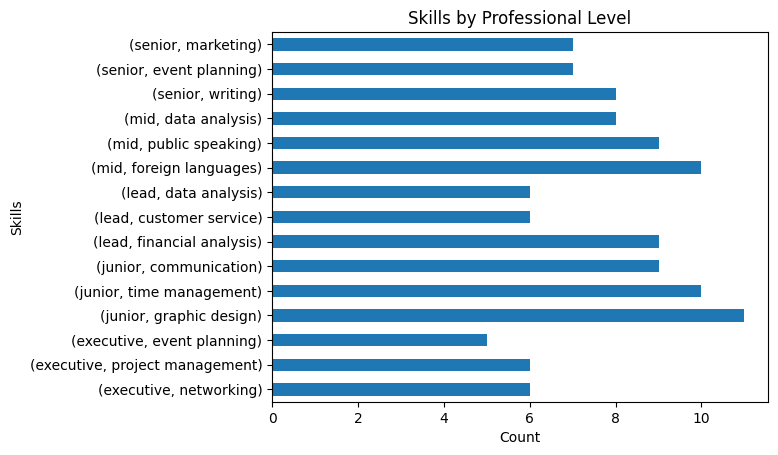

In [23]:
#Most common skills by professional level
skills_by_level = (
    resume_f.groupby('professional level')['skills'].value_counts().groupby(level=0).head(3))
#Create series object - grouped by professional level; then select skills
# Take value counts of skills by professional level; group by first level of professional level
# Then show the top 3 skills per professional level

print(skills_by_level) #Display series - top 3 skills by professional level with # occurrences
print(type(skills_by_level)) #Check data type of skills_by_level object
skills_by_level.plot(kind='barh') #Plot skills_by_ level series as bar chart
#Add labels
plt.title("Skills by Professional Level")
plt.xlabel("Count")
plt.ylabel("Skills")
plt.show()

Citation: https://www.geeksforgeeks.org/python/python-pearsons-chi-square-test/

In [24]:
#Perform chi-square test to determine if relationship between professional level and skills

skills_df = resume_f[['professional level', 'skills']] #Create dataframe of only relevant info

#Create contingency/pivot table for statistical testing (from pandas)
contingency = skills_df.pivot_table(
    index='skills',  # each skill = row
    columns='professional level',  # each level = column
    aggfunc='size'               # count observed frequency
)

print(contingency.head()) #Print generated pivot table to check construction

from scipy.stats import chi2_contingency #import necessary capability

chi2, p_value, dof, expected = chi2_contingency(contingency) #Run chi-square test on generated pivot table

#Print results
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_value)

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Skill distributions differ by professional level.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that skill distributions differ by level.")

#Why getting nan for Chi-square and p-value? Data is too sparse

#Time to fix:
skill_count = skills_df['skills'].value_counts()
freq_skills = skill_count[skill_count >= 25].index
skills_df_freq = skills_df[skills_df['skills'].isin(freq_skills)]

#Create new filtered contingency table and run analysis
contingency_f = skills_df_freq.pivot_table(
    index='skills',
    columns='professional level',
    aggfunc='size'
)

print(contingency_f.head())

chi2_f, p_value_f, dof_f, expected_f = chi2_contingency(contingency_f)

#Print results
print("Chi-square statistic:", chi2_f)
print("Degrees of freedom:", dof_f)
print("p-value:", p_value_f)

#This can also likely be due to the artifical nature of the data, but unable to generate a chi-square value
# For the skills even with frequency counts, likely due to sparsity of data
# Other techniques could combine the professional levels, but would like to preserve that division.

professional level  executive  junior  lead  mid  senior
skills                                                  
communication             2.0     9.0   5.0  4.0     4.0
creativity                3.0     4.0   3.0  4.0     2.0
critical thinking         1.0     2.0   5.0  4.0     3.0
customer service          4.0     9.0   6.0  5.0     4.0
data analysis             1.0     8.0   6.0  8.0     5.0
Chi-square statistic: nan
Degrees of freedom: 116
p-value: nan
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that skill distributions differ by level.
professional level  executive  junior  lead  mid  senior
skills                                                  
customer service          4.0     9.0   6.0  5.0     4.0
data analysis             1.0     8.0   6.0  8.0     5.0
event planning            5.0     6.0   NaN  7.0     7.0
graphic design            3.0    11.0   4.0  5.0     5.0
networking                6.0     9.0   5.0  5.0     4.0
Chi-square statist

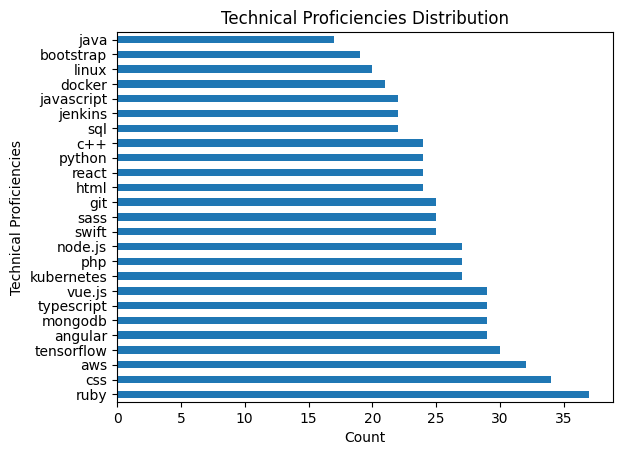

In [25]:
#Plot technical proficiencies distribution (frequency)
resume_f['technical_proficiencies'].value_counts().plot(kind='barh')
#Add labels
plt.title("Technical Proficiencies Distribution")
plt.xlabel("Count")
plt.ylabel("Technical Proficiencies")
plt.show()

professional level  technical_proficiencies
executive           python                      7
                    ruby                        7
                    tensorflow                  6
junior              css                        12
                    aws                        10
                    react                      10
lead                git                         9
                    css                         8
                    typescript                  7
mid                 aws                        10
                    html                       10
                    ruby                       10
senior              jenkins                     8
                    vue.js                      8
                    git                         7
Name: count, dtype: int64
<class 'pandas.core.series.Series'>


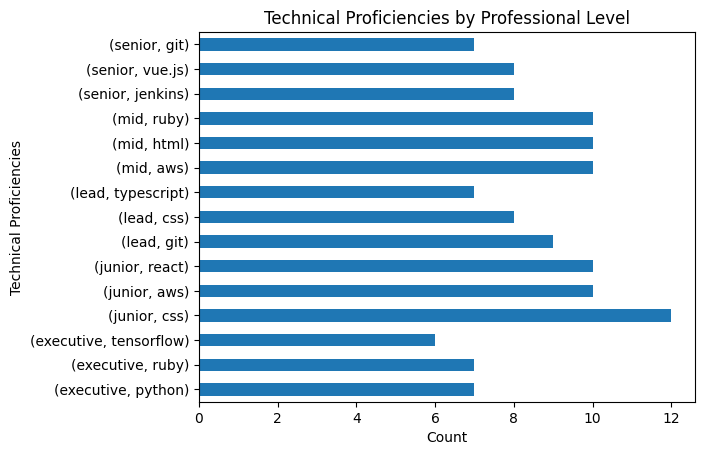

In [26]:
#Most common technical proficiencies by professional level
tech_by_level = (
    resume_f.groupby('professional level')['technical_proficiencies'].value_counts().groupby(level=0).head(3))
#Create series object - grouped by professional level; then select technical proficiencies
# Take value counts of technical proficiencies by professional level; group by first level of professional level
# Then show the top 3 technical proficiencies per professional level

print(tech_by_level) #Display series - top 3 technical proficiencies by professional level with # occurrences
print(type(tech_by_level)) #Check data type of tech_by_level object
tech_by_level.plot(kind='barh') #Plot tech_by_level series as bar chart
#Add labels
plt.title("Technical Proficiencies by Professional Level")
plt.xlabel("Count")
plt.ylabel("Technical Proficiencies")
plt.show()

In [27]:
#Perform chi-square test to determine if relationship between professional level and technical proficiencies

tech_df = resume_f[['professional level', 'technical_proficiencies']] #Create dataframe of only relevant info

#Create contingency/pivot table for statistical testing (from pandas)
contingency_t = tech_df.pivot_table(
    index='technical_proficiencies',  # each skill = row
    columns='professional level',  # each level = column
    aggfunc='size'               # count observed frequency
)

print(contingency_t.head()) #Print generated pivot table to check construction

chi2_t, p_value_t, dof_t, expected_t = chi2_contingency(contingency_t) #Run chi-square test on generated pivot table

#Print results
print("Chi-square statistic:", chi2_t)
print("Degrees of freedom:", dof_t)
print("p-value:", p_value_t)

#Interpret results
if p_value_t < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Technical proficiency distributions differ by professional level.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that technical proficiency distributions differ by level.")

#Why getting nan for Chi-square and p-value? Data is too sparse

#Time to fix:
tech_count = tech_df['technical_proficiencies'].value_counts()
#Count technical proficiencies frequency, keep only >= 20 times appear
freq_tech = tech_count[tech_count >= 20].index
tech_df_freq = tech_df[tech_df['technical_proficiencies'].isin(freq_tech)]

#Create new filtered contingency table and run analysis
contingency_t2 = tech_df_freq.pivot_table(
    index='technical_proficiencies',
    columns='professional level',
    aggfunc='size'
)

print(contingency_t2.head())

chi2_t2, p_value_t2, dof_t2, expected_t2 = chi2_contingency(contingency_t2)

#Print results
print("Chi-square statistic:", chi2_t2)
print("Degrees of freedom:", dof_t2)
print("p-value:", p_value_t2)

#This can also likely be due to the artifical nature of the data, but unable to generate a chi-square value
# For the technical proficiencies even with frequency counts, likely due to sparsity of data
# Other techniques could combine the professional levels, but would like to preserve that division.

professional level       executive  junior  lead   mid  senior
technical_proficiencies                                       
angular                        3.0     8.0   4.0   8.0     6.0
aws                            4.0    10.0   6.0  10.0     2.0
bootstrap                      NaN     5.0   4.0   6.0     4.0
c++                            3.0     8.0   3.0   7.0     3.0
css                            3.0    12.0   8.0   7.0     4.0
Chi-square statistic: nan
Degrees of freedom: 96
p-value: nan
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that technical proficiency distributions differ by level.
professional level       executive  junior  lead   mid  senior
technical_proficiencies                                       
angular                        3.0     8.0   4.0   8.0     6.0
aws                            4.0    10.0   6.0  10.0     2.0
c++                            3.0     8.0   3.0   7.0     3.0
css                            3.0    12.0   

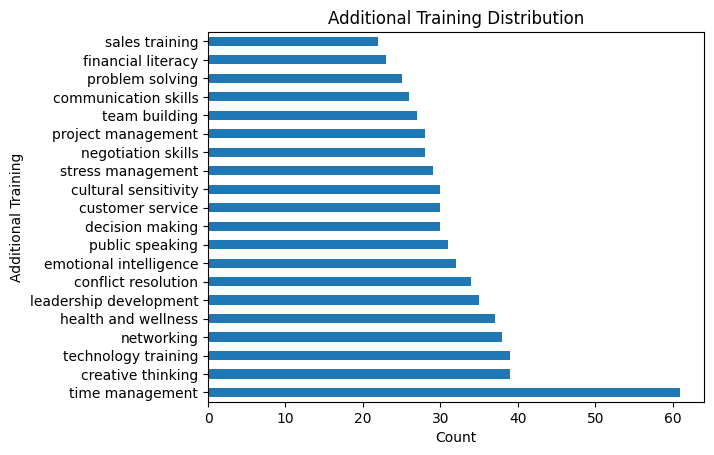

In [28]:
#Plot additional training distribution (frequency)
resume_f['additional_training'].value_counts().plot(kind='barh')
#Add labels
plt.title("Additional Training Distribution")
plt.xlabel("Count")
plt.ylabel("Additional Training")
plt.show()

professional level  additional_training   
executive           time management           17
                    technology training        6
                    emotional intelligence     5
junior              networking                16
                    technology training       15
                    health and wellness       14
lead                time management           19
                    creative thinking          8
                    cultural sensitivity       7
mid                 health and wellness       13
                    leadership development    13
                    time management           11
senior              emotional intelligence    10
                    networking                10
                    decision making            9
Name: count, dtype: int64
<class 'pandas.core.series.Series'>


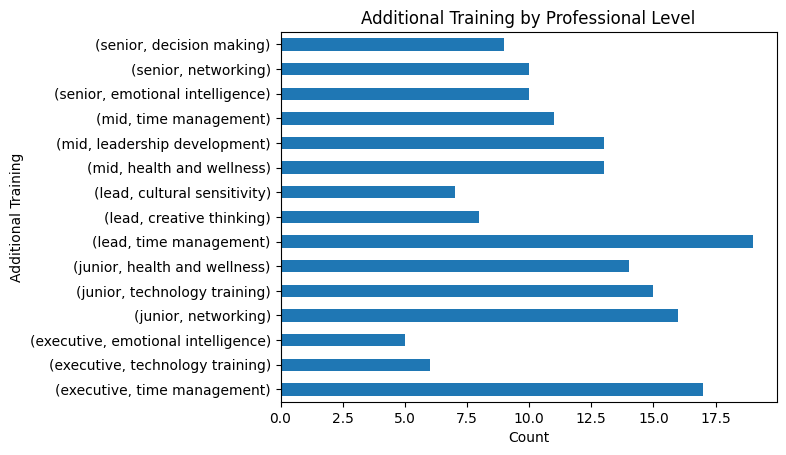

In [29]:
#Most common training by professional level
training_by_level = (
    resume_f.groupby('professional level')['additional_training'].value_counts().groupby(level=0).head(3))
#Create series object - grouped by professional level; then select additional training
# Take value counts of additional training by professional level; group by first level of professional level
# Then show the top 3 additional training per professional level

print(training_by_level) #Display series - top 3 additional training by professional level with # occurrences
print(type(training_by_level))#Check data type of training_by_level object
training_by_level.plot(kind='barh') #Plot training_by_level series as a bar chart
#Add labels
plt.title("Additional Training by Professional Level")
plt.xlabel("Count")
plt.ylabel("Additional Training")
plt.show()

In [30]:
#Perform chi-square test to determine if relationship between professional level and additional training

train_df = resume_f[['professional level', 'additional_training']] #Create dataframe of only relevant info

#Create contingency/pivot table for statistical testing (from pandas)
contingency_tr = train_df.pivot_table(
    index='additional_training',  # each skill = row
    columns='professional level',  # each level = column
    aggfunc='size'               # count observed frequency
)

print(contingency_tr.head()) #Print generated pivot table to check construction

chi2_tr, p_value_tr, dof_tr, expected_tr = chi2_contingency(contingency_tr) #Run chi-square test on generated pivot table

#Print results
print("Chi-square statistic:", chi2_tr)
print("Degrees of freedom:", dof_tr)
print("p-value:", p_value_tr)

#Interpret results
if p_value_tr < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Additional training distributions differ by professional level.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that additional training distributions differ by level.")


# There is a difference in training for different professional levels - pursue

professional level    executive  junior  lead  mid  senior
additional_training                                       
communication skills          3       3     6    6       8
conflict resolution           4      12     3    9       6
creative thinking             4      13     8   10       4
cultural sensitivity          4       7     7    8       4
customer service              3       6     5   10       6
Chi-square statistic: 98.32050194233511
Degrees of freedom: 76
p-value: 0.0435058876724647
Result: REJECT the null hypothesis.
Interpretation: Additional training distributions differ by professional level.


ARE THERE DIFFERENCES BETWEEN RESUMES ACCEPTED AND NOT ACCEPTED?

In [31]:
counts = resume_f['job_accepted'].value_counts()

print("Accepted/Rejected Resume Counts")
print(f"Total Accepted (1): {counts.get(1, 0)}")
print(f"Total Rejected (0): {counts.get(0, 0)}")

#Pure numbers being the same does not necessarily imply that there are no differences though

Accepted/Rejected Resume Counts
Total Accepted (1): 413
Total Rejected (0): 231


In [32]:
#Check years of experience
from scipy.stats import shapiro, mannwhitneyu

#check normality of years of experience with shapiro test
years_exp = resume_f['experience_years'].dropna()
stat, p = shapiro(years_exp)
print(f"W-Stat: {stat:.3f}")
print(f"P-Value: {p:.4f}")
is_normal = p > 0.05
print(f"Is years of experience normally distributed? {is_normal}")

#Create two groups, where resume is accepted or not accepted, and the connected years of experience
accepted = resume_f[resume_f['job_accepted'] == True]['experience_years']
not_accepted = resume_f[resume_f['job_accepted'] == False]['experience_years']

#Since not normally distributed, proceed with Mann-Whitney test
stat_mw, p_mw = mannwhitneyu(accepted, not_accepted, alternative='two-sided')
print(f"Test-Stat: {stat_mw:.3f}")
print(f"P-Value: {p_mw:.4f}")

if p_mw < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: There is a significant difference in years of experience between accepted and not accepted resumes.")
else:
    print("Result: FAIL TO REJECT the null hypothesis. Difference in years of experience between groups not statistically significant.")

#Years of experience is not normally distributed, which follows the visualization shown in EDA
# Differences in years of experience between accepted/rejected resumes is statistically significant
# Can influence the outcome of a resume being accepted as there is a difference
# However, years of experience could be desired in different ranges for different positions, but likely to see more experience, more acceptance as general trend


W-Stat: 0.961
P-Value: 0.0000
Is years of experience normally distributed? False
Test-Stat: 52602.500
P-Value: 0.0303
Result: REJECT the null hypothesis.
Interpretation: There is a significant difference in years of experience between accepted and not accepted resumes.


In [33]:
#Check age

#check normality of age of experience with shapiro test
years_age = resume_f['age'].dropna()
stat, p = shapiro(years_age)
print(f"W-Stat: {stat:.3f}")
print(f"P-Value: {p:.4f}")
is_normal = p > 0.05
print(f"Is age (years) normally distributed? {is_normal}")

#Create two groups, where resume is accepted or not accepted, and the connected age of applicant
accepted = resume_f[resume_f['job_accepted'] == True]['age']
not_accepted = resume_f[resume_f['job_accepted'] == False]['age']

#Since not normally distributed, proceed with Mann-Whitney test
stat_mw, p_mw = mannwhitneyu(accepted, not_accepted, alternative='two-sided')
print(f"Test-Stat: {stat_mw:.3f}")
print(f"P-Value: {p_mw:.4f}")

if p_mw < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: There is a significant difference in age of applicant between accepted and not accepted resumes.")
else:
    print("Result: FAIL TO REJECT the null hypothesis. Difference in age of applicant between groups not statistically significant.")

#Age of applicant is not normally distributed, which follows the visualization shown in EDA
# Differences in age of applicant between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
#Also a flaw with the data and technique - different ages could be desirable for different positions

W-Stat: 0.974
P-Value: 0.0000
Is age (years) normally distributed? False
Test-Stat: 49061.500
P-Value: 0.5482
Result: FAIL TO REJECT the null hypothesis. Difference in age of applicant between groups not statistically significant.


In [34]:
#Check github contributions

#check normality of github contributions with shapiro test
gh = resume_f['github_contributions'].dropna()
stat, p = shapiro(gh)
print(f"W-Stat: {stat:.3f}")
print(f"P-Value: {p:.4f}")
is_normal = p > 0.05
print(f"Are GitHub contributions normally distributed? {is_normal}")

#Create two groups, where resume is accepted or not accepted, and the connected number of github contributions
accepted = resume_f[resume_f['job_accepted'] == True]['github_contributions']
not_accepted = resume_f[resume_f['job_accepted'] == False]['github_contributions']

#Since not normally distributed, proceed with Mann-Whitney test
stat_mw, p_mw = mannwhitneyu(accepted, not_accepted, alternative='two-sided')
print(f"Test-Stat: {stat_mw:.3f}")
print(f"P-Value: {p_mw:.4f}")

if p_mw < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: There is a significant difference in number of GitHub contributions between accepted and not accepted resumes.")
else:
    print("Result: FAIL TO REJECT the null hypothesis. Difference in number of GitHub contributions between groups not statistically significant.")

#Number of Github contributions is not normally distributed
# Differences in number of github contributions between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
#Also a flaw with the data and technique - might not be relevant for all positions

W-Stat: 0.954
P-Value: 0.0000
Are GitHub contributions normally distributed? False
Test-Stat: 46940.000
P-Value: 0.7368
Result: FAIL TO REJECT the null hypothesis. Difference in number of GitHub contributions between groups not statistically significant.


How does the level of education impact a candidate's likelihood of receiving a callback?

Average Callback Rate by Education Level:

education_level
trade school certificate      0.754386
ged                           0.734375
associate's degree            0.733333
high school diploma           0.723404
some college                  0.716418
master's degree               0.706667
phd                           0.673913
technical degree              0.660714
professional certification    0.632653
bachelor's degree             0.600000
no degree                     0.232877
Name: job_accepted, dtype: float64


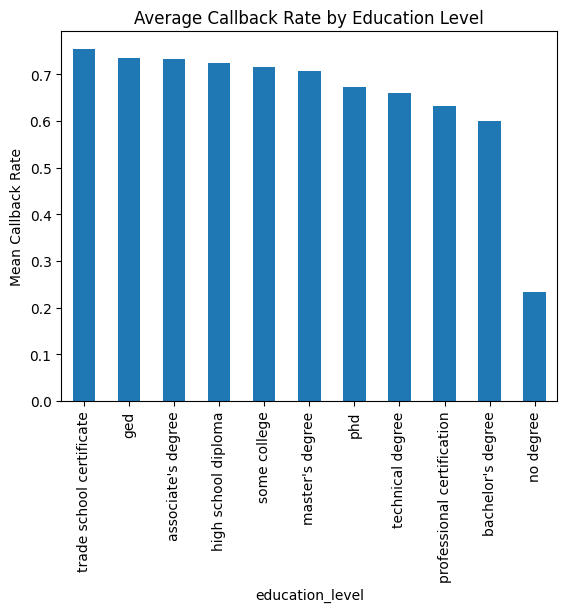

job_accepted                 0   1
education_level                   
associate's degree          12  33
bachelor's degree           26  39
ged                         17  47
high school diploma         13  34
master's degree             22  53
no degree                   56  17
phd                         15  31
professional certification  18  31
some college                19  48
technical degree            19  37
trade school certificate    14  43
Chi-square statistic: 65.389
Degrees of freedom: 10
P-value: 0.00000
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that accepted vs rejected resumes differ by educational level.


In [35]:
# Use the already cleaned resume_f dataframe, make copy for clarity
df = resume_f.copy()

# Calculate callback rate by education level
edu_callback = (df.groupby("education_level")["job_accepted"].mean().sort_values(ascending=False)
) #Group resumes by education level, select if accepted to job, find average rate of acceptances per group

print("Average Callback Rate by Education Level:\n")
print(edu_callback)

edu_callback.plot(kind="bar") #Plot average callback rate by educational level as barchart
#Add labels
plt.title("Average Callback Rate by Education Level")
plt.ylabel("Mean Callback Rate")
plt.show()

#Chi-square test - is there a statistically significant relationship between education level and callback?
contingency = pd.crosstab(df["education_level"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by educational level.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by educational level.")

# Differences in educational level between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
# Likely due to artifical nature of data, but also flaw with not knowing the job being applied to
#Would expect to see higher acceptance for more prestigious degrees. Institution could also affect outcome.

Does having references available increase callback probability?

In [36]:
ref_callback = (df.groupby("references_available")["job_accepted"].mean())
#Create series object where resume dataset is grouped by references available, and find mean rate of job acceptance
print(type(ref_callback)) #Check object type

#Print results
print("\nCallback Rate by References Available (TRUE/FALSE):\n")
print(ref_callback)

#Chi-square test - is there a statistically significant relationship between references being available and callback?
contingency = pd.crosstab(df["references_available"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by references being available.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by having references available.")

# Differences in references being available between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance

<class 'pandas.core.series.Series'>

Callback Rate by References Available (TRUE/FALSE):

references_available
False    0.631579
True     0.651090
Name: job_accepted, dtype: float64
job_accepted            0    1
references_available          
False                 119  204
True                  112  209
Chi-square statistic: 0.188
Degrees of freedom: 1
P-value: 0.66427
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that accepted vs rejected resumes differ by having references available.


How does callback rate differ by professional level (junior, mid, senior, lead, executive)?

In [37]:
prof_callback = (df.groupby("professional level")["job_accepted"].mean().sort_values(ascending=False))
#Create series object where resume dataset is grouped by professional level, and find mean rate of job acceptance

#print results
print("\nAverage Callback Rate by Professional Level:\n")
print(prof_callback)

#Chi-square test -  is there a statistically significant relationship between professional level and callback?
contingency = pd.crosstab(df["professional level"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by professional level.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by professional level.")

# Differences in professional level between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
# Likely due to artifical nature of data, but also flaw with not knowing the job being applied to
#Would expect to see higher acceptance for higher level employees. Institution could also affect outcome.


Average Callback Rate by Professional Level:

professional level
executive    1.000000
lead         1.000000
junior       0.526316
senior       0.491525
mid          0.423077
Name: job_accepted, dtype: float64
job_accepted         0    1
professional level         
executive            0   86
junior              81   90
lead                 0  113
mid                 90   66
senior              60   58
Chi-square statistic: 164.938
Degrees of freedom: 4
P-value: 0.00000
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that accepted vs rejected resumes differ by professional level.


In [38]:
#Chi-square test -  is there a statistically significant relationship between skills and callback?
contingency = pd.crosstab(df["skills"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by skills.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by skills.")

# Differences in professional level between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
# Likely due to artifical nature of data, but also flaw with not knowing the job being applied to, and only having one skill per resume

job_accepted              0   1
skills                         
communication             5  19
creativity                4  12
critical thinking         6   9
customer service          8  20
data analysis             9  19
design                   11  10
event planning            9  16
financial analysis        4  16
foreign languages        13  11
graphic design           11  17
leadership                5  13
marketing                 4  15
negotiation               6   8
networking               13  16
photography               7  10
problem solving           9  16
programming               8  13
project management        9  12
public relations          4  10
public speaking          12  14
research                  8  14
sales                    12  11
seo                       4  16
social media management  12  13
strategic planning        4  16
teamwork                  5  14
time management          14   9
video editing             2  13
web development           8  10
writing 

In [39]:
#Chi-square test -  is there a statistically significant relationship between languages known and callback?
contingency = pd.crosstab(df["languages_spoken"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by languages spoken.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by languages spoken.")

# Differences in languages spoken between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
# Likely due to artifical nature of data, but also flaw with not knowing the job being applied to, and only having one language per resume

job_accepted       0   1
languages_spoken        
arabic            11  16
bengali           11  14
czech              7  17
dutch             11  20
english            2  15
finnish            8  13
french             9  14
german             9  18
greek             11  13
hebrew            12  14
hindi             12  18
italian           10  15
japanese          11  17
korean             5  20
mandarin          12  18
polish             7  16
portuguese        10  15
russian           13  16
spanish            8  16
swahili           10  20
swedish            7  22
tagalog           10  10
thai               8  24
turkish           13  17
vietnamese         4  15
Chi-square statistic: 21.027
Degrees of freedom: 24
P-value: 0.63711
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that accepted vs rejected resumes differ by languages spoken.


In [40]:
#Chi-square test -  is there a statistically significant relationship between technical proficiencies and callback?
contingency = pd.crosstab(df["technical_proficiencies"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by technical proficiencies.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by technical proficiencies.")

# Differences in technical proficiencies between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
# Likely due to artifical nature of data, but also flaw with not knowing the job being applied to, and only having one technical proficiency per resume

job_accepted              0   1
technical_proficiencies        
angular                   9  20
aws                      13  19
bootstrap                 8  11
c++                      11  13
css                      13  21
docker                   10  11
git                       6  19
html                      4  20
java                      6  11
javascript                7  15
jenkins                   8  14
kubernetes               14  13
linux                    10  10
mongodb                   8  21
node.js                  12  15
php                      10  17
python                    8  16
react                     8  16
ruby                      9  28
sass                      9  16
sql                       4  18
swift                    10  15
tensorflow               10  20
typescript               11  18
vue.js                   13  16
Chi-square statistic: 21.933
Degrees of freedom: 24
P-value: 0.58329
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No stro

In [41]:
#Chi-square test -  is there a statistically significant relationship between additional training and callback?
contingency = pd.crosstab(df["additional_training"], df["job_accepted"]) #Create contingency table
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency) #Run chi-square test

#Print results
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.5f}")

#Interpret results
if p_value < 0.05:
    print("Result: REJECT the null hypothesis.")
    print("Interpretation: Accepted vs rejected resumes differ by additional training.")
else:
    print("Result: FAIL TO REJECT the null hypothesis.")
    print("Interpretation: No strong evidence that accepted vs rejected resumes differ by additional training.")

# Differences in additional training between accepted/rejected resumes not statistically significant, could occur by chance
# Not able to interpret as a key factor in determining acceptance
# Likely due to artifical nature of data, but also flaw with not knowing the job being applied to, and only having one training per resume

job_accepted             0   1
additional_training           
communication skills    10  16
conflict resolution     18  16
creative thinking       14  25
cultural sensitivity    12  18
customer service        11  19
decision making         14  16
emotional intelligence  12  20
financial literacy      10  13
health and wellness     16  21
leadership development  12  23
negotiation skills      10  18
networking              12  26
problem solving          9  16
project management       9  19
public speaking         13  18
sales training           6  16
stress management       12  17
team building            5  22
technology training      9  30
time management         17  44
Chi-square statistic: 17.728
Degrees of freedom: 19
P-value: 0.54067
Result: FAIL TO REJECT the null hypothesis.
Interpretation: No strong evidence that accepted vs rejected resumes differ by additional training.


Principal Component Analysis  &  Data Scaling/Encoding/Pre-processing

Citation: https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-with-python/

Citation: https://www.geeksforgeeks.org/machine-learning/implementing-pca-in-python-with-scikit-learn/

In [42]:
#Import necessary capabilities
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, RocCurveDisplay

In [43]:
num_cols = ['age', 'experience_years', 'github_contributions']
ord_cols = ['edu_rank', 'level_rank']
nom_cols = ['skills', 'languages_spoken', 'technical_proficiencies', 'additional_training']

# Combine all feature columns into a single list
all_features = num_cols + ord_cols + nom_cols

# Define features (X) and target (y)
X = resume_f[all_features]
y = resume_f['job_accepted']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Pre-processing pipeline - numerical
numerical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pre-processing pipeline - ordinal
ordinal_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

#ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num_pipe', numerical_pipe, num_cols), #apply numerical pipeline to numerical columns
        ('ord_pipe', ordinal_pipe, ord_cols), #Apply ordinal pipeline to ordinal columns
        ('nom_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), nom_cols) #Apply OHE to nominal columns
    ],
    remainder='drop' # Only include the columns pulled out
)

# PCA final pipeline
pca = PCA(n_components = 4)
pca_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), #Run pre-processor
    ('pca', pca) #Apply pca
])

#Train and test
X_train_transformed_pca = pca_pipeline.fit_transform(X_train, y_train)
X_test_transformed_pca = pca_pipeline.transform(X_test)

# Results
expl_var = pca.explained_variance_ratio_
print(expl_var)

#Top 4 components explain (0.16+0.117+0.112+0.096 = 0.485) almost half of the variance
#Question is which components actually contribute, which I cannot figure out how to properly code for :(

[0.16367265 0.11765061 0.11202596 0.09583066]


Machine Learning

How accurately can ML models predict a callback?


Logistic Regression

Citation: https://www.geeksforgeeks.org/machine-learning/ml-logistic-regression-using-python/

Citation: https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-with-python/

Citation: https://www.geeksforgeeks.org/machine-learning/using-columntransformer-in-scikit-learn-for-data-preprocessing/

In [44]:
#Import necessary capabilities
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, auc

Accuracy: 0.6666666666666666
Confusion Matrix:
 [[20 22]
 [21 66]]
ROC-AUC Score: 0.7148330596606458


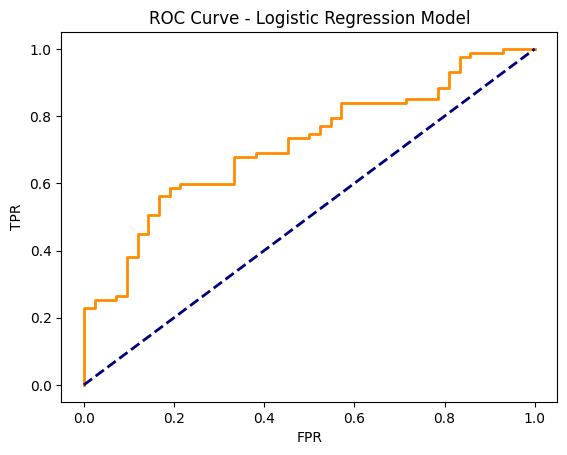

In [45]:
# Define numerical and categorical features
numerical_features = ['age', 'experience_years', 'github_contributions', 'edu_rank', 'level_rank'] #matrix of numerical features
categorical_features = ['skills', 'languages_spoken', 'technical_proficiencies', 'additional_training'] #matrix of categorical features

# Create a preprocessor using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features), #Scale numerical features with a standard scaler
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features) #OHE for categorical features
    ])

# Create a pipeline with the preprocessor and Logistic Regression model
log_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), #apply preprocessing steps
    ('classifier', LogisticRegression(random_state=42, max_iter=1000)) #then run logistic regression model
  ])

# Split data into training and testing sets
X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit the pipeline
log_pipeline.fit(X_train_l, y_train_l)

# Predict results
y_pred_log = log_pipeline.predict(X_test_l)

# Accuracy
acc_l = accuracy_score(y_test_l, y_pred_log)
print("Accuracy:", acc_l)

#Interpret
#Accuracy = 66.67%; performs slightly better than chance, but still lots of errors

# Confusion matrix
cm_log = confusion_matrix(y_test_l, y_pred_log)
print("Confusion Matrix:\n", cm_log)

#Interpret
#True negative: 20 (ok at predicting true negatives, but not much better than false discrimination)
#False positive: 22
#False negative: 21
#True positive: 66 (best at predicting true positives) - there are more accepted resumes included
#Stil lots of misclassifications, though no difference in type 1 vs type 2 error rate
#Reflects accuracy still close to chance rate

# ROC-AUC score
y_prob_l = log_pipeline.predict_proba(X_test_l)[:, 1]
fpr_l, tpr_l, thresholds_l = roc_curve(y_test_l, y_prob_l)
roc_auc_l = auc(fpr_l, tpr_l)
print("ROC-AUC Score:", roc_auc_l)

#Interpret
#ROC-AUC = 0.7; model is acceptable and able to discriminate, but has issues

# Plot ROC curve
plt.figure()
plt.plot(fpr_l, tpr_l, color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve - Logistic Regression Model")
plt.show()

Random Forest Model

Accuracy: 0.7054263565891473
ROC-AUC Score: 0.8103448275862069


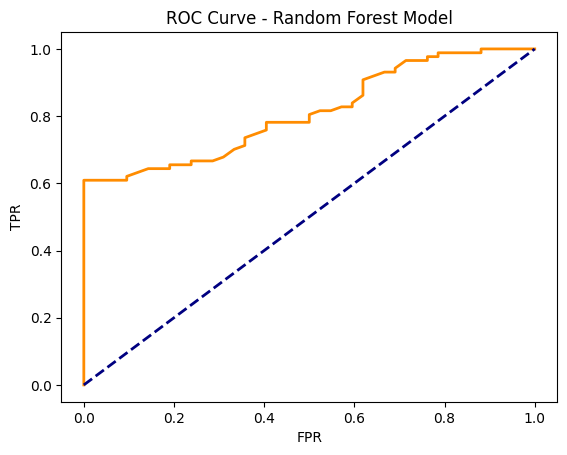

[0.06449912 0.05727995 0.07015628 0.11601473 0.19553596 0.00440918
 0.00306184 0.00384846 0.00425715 0.00527606 0.00479691 0.0060055
 0.00417559 0.00756177 0.00508917 0.0050773  0.00473639 0.00269822
 0.00669179 0.00372695 0.00553349 0.00474157 0.00406291 0.00283012
 0.00417304 0.00563926 0.00461492 0.00350866 0.00781714 0.00444936
 0.0037613  0.01021805 0.00181406 0.00396214 0.00564007 0.0051622
 0.00524053 0.00415109 0.00561409 0.00491876 0.0035065  0.00427143
 0.003825   0.00304489 0.00486747 0.00396389 0.00431861 0.00829273
 0.00482662 0.00573746 0.00381165 0.00516774 0.00580858 0.00440475
 0.00508444 0.00488146 0.00778376 0.00594389 0.00653482 0.00323448
 0.00473659 0.00540774 0.00362857 0.00616055 0.0050547  0.00487938
 0.00313112 0.00329788 0.00326718 0.00452679 0.00373151 0.00619842
 0.00515394 0.00460055 0.0047195  0.00582942 0.00438995 0.00464061
 0.00678574 0.00362426 0.0053042  0.00581316 0.00483962 0.00431168
 0.00425926 0.00456493 0.0062977  0.00529817 0.00453265 0.006293

In [46]:
# Create RF model
rf_pipeline = Pipeline(steps = [
    ("prep", preprocessor), #apply preprocessing steps
    ("rf", RandomForestClassifier(n_estimators=200, random_state=42)) #then run random forest model
])

# Split data into training and testing sets
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(X, y, test_size=0.2, random_state=42)

#Fit model
rf_pipeline.fit(X_train_rf, y_train_rf)

pred_rf = rf_pipeline.predict(X_test_rf)
prob_rf = rf_pipeline.predict_proba(X_test_rf)[:, 1]

#Accuracy
acc_rf = accuracy_score(y_test_rf, pred_rf)
print("Accuracy:", acc_rf)

#Interpret
#Accuracy = 70.54%; quite successful model with room for improvement. More successful than logistic regression

#ROC-AUC score
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test_rf, prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)
print("ROC-AUC Score:", roc_auc_rf)

#Interpret
#ROC-AUC = 0.8; model is acceptable and able to discriminate, but has issues. More successful than logistic regression

# Plot ROC curve
plt.figure()
plt.plot(fpr_rf, tpr_rf, color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Curve - Random Forest Model")
plt.show()

print(rf_pipeline.named_steps['rf'].feature_importances_)
#Shows the importance of each feature to the prediction
#However, I am struggling to put together a reconstruction that shows which features these correspond to

In [47]:
#Commentary
#Other models worth investigating include GLM

K-Prototypes Clustering

Citation: https://obrunet.github.io/data%20science/kproto/

In [50]:
!pip install kmodes

In [51]:
from kmodes.kprototypes import KPrototypes

In [52]:
# Rule to run only on accepted resumes
accepted_mask = y_train_rf == 1

# Filter the raw feature training data (X_train_rf) using the target mask
X_train_accepted_raw = X_train_rf[accepted_mask].copy()

# Define a preprocessor specifically for kprototypes
preprocessor_for_kproto = ColumnTransformer(
    transformers=[
        ('num_scaled', StandardScaler(), num_cols),
        ('ord_scaled', StandardScaler(), ord_cols),
        ('cat_encoded', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), nom_cols)
    ],
    remainder='drop'
)

# Transform
X_kproto_transformed = preprocessor_for_kproto.fit_transform(X_train_accepted_raw)

# Determine the indices of the categorical columns in the X_kproto_transformed array
categorical_start_idx = len(num_cols) + len(ord_cols)
categorical_indices = list(range(categorical_start_idx, X_kproto_transformed.shape[1]))

# make sure numerical features are float and categorical features are integer, then combine
X_kproto_numerical_part = X_kproto_transformed[:, :categorical_start_idx].astype(float)
X_kproto_categorical_part = X_kproto_transformed[:, categorical_start_idx:].astype(int)

X_kproto_accepted = np.concatenate((X_kproto_numerical_part, X_kproto_categorical_part), axis=1)


In [53]:
#Elbow plot to find optimal number of clusters (where cost starts to "bend")
costs = []
import numpy as np
import scipy.sparse as sparse

# Ensure X_kproto_accepted is a dense numpy array
if sparse.issparse(X_kproto_accepted):
    X_kproto_ready = X_kproto_accepted.toarray()
else:
    X_kproto_ready = X_kproto_accepted

for nb_cluster in range(1, 10):
        kprototype = KPrototypes(n_clusters=nb_cluster, random_state=0)
        kprototype.fit_predict(X_kproto_ready, categorical=categorical_indices)
        costs.append(kprototype.cost_)
        print(f'Nb of cluster: {nb_cluster}, cost: {kprototype.cost_}')

Nb of cluster: 1, cost: 2237.0
Nb of cluster: 2, cost: 1878.728127412772
Nb of cluster: 3, cost: 1688.7752933462539
Nb of cluster: 4, cost: 1565.7824966133865
Nb of cluster: 5, cost: 1477.6299605331408
Nb of cluster: 6, cost: 1407.2929295709903
Nb of cluster: 7, cost: 1352.0913864475951
Nb of cluster: 8, cost: 1301.0440668962947
Nb of cluster: 9, cost: 1250.538790712546


In [54]:
# Replace 4 with the optimal K determined from the Elbow Plot
optimal_k = 4

kproto_final = KPrototypes(n_jobs = -1, n_clusters=optimal_k, random_state=42)

# Fit the model to the data, using X_kproto_accepted (accepted resumes only)
clusters = kproto_final.fit_predict(X_kproto_accepted, categorical=categorical_indices)

print(clusters)
print(kproto_final)
print(kproto_final.cluster_centroids_)
print(kproto_final.n_iter_)

[3 1 2 3 0 3 1 0 3 0 1 1 0 2 2 3 1 2 2 0 0 1 0 3 2 2 0 2 1 3 0 3 1 2 1 2 3
 1 1 2 1 3 3 2 3 3 1 0 0 3 1 3 3 0 3 1 0 3 1 1 3 2 3 3 2 0 1 3 0 0 3 3 2 2
 2 2 0 1 3 0 1 1 0 0 1 1 3 0 1 3 0 0 1 1 3 0 0 3 3 1 0 1 3 1 0 2 1 0 0 0 1
 0 2 3 0 0 3 2 3 3 1 2 1 2 0 1 3 1 3 3 2 0 3 0 2 1 2 3 1 3 2 3 3 1 1 1 3 1
 0 3 0 0 1 3 3 3 1 1 3 3 3 1 3 0 3 2 3 2 1 3 0 2 2 3 3 0 1 2 1 3 0 1 3 0 0
 3 2 3 1 3 2 0 1 0 1 1 0 1 3 0 2 3 3 2 3 1 3 3 0 2 0 1 3 3 1 3 3 0 0 2 0 1
 0 1 0 3 1 2 1 0 3 2 2 1 1 0 2 2 3 1 3 3 0 3 0 2 1 3 3 3 2 0 1 3 1 1 1 1 0
 1 3 1 0 2 3 3 2 0 3 3 0 0 2 0 3 2 0 1 1 3 3 3 2 0 0 2 1 1 1 3 2 1 1 0 3 2
 2 3 0 0 1 3 0 0 2 0 0 3 1 1 2 0 1 0 3 3 0 3 2 0 2 1 3 1 1 0]
KPrototypes(gamma=np.float64(0.5), n_clusters=4, n_jobs=-1, random_state=42)
[[-3.44511611e-02  3.05558821e-01 -7.89045497e-01 -8.51423266e-01
   6.84231460e-01  1.50000000e+01  1.30000000e+01  2.20000000e+01
   1.90000000e+01]
 [ 4.86920015e-01  4.48843333e-01  1.10162436e+00  9.43892734e-02
   3.31257948e-01  0.00000000e+00  1.4000000

In [55]:
# Add the cluster labels back to the original training features for analysis
# The clusters were generated for X_train_accepted_raw, so assign them there.
X_train_accepted_raw['Cluster'] = clusters

In [56]:
# Separate numerical and categorical columns
num_cols_for_analysis = ['age', 'experience_years', 'github_contributions', 'edu_rank', 'level_rank']
cat_cols_for_analysis = ['skills', 'languages_spoken', 'technical_proficiencies', 'additional_training']

print("\nCluster Centroids (Numerical Means)")
cluster_analysis_num = X_train_accepted_raw.groupby('Cluster')[num_cols_for_analysis].mean() #mean for numericals
print(cluster_analysis_num)

print("\nCluster Modes (Categorical Feature Frequencies)")
for col in cat_cols_for_analysis:
    print(f"\nTop 3 Modes for: {col}") #mode for categorical
    cluster_modes = X_train_accepted_raw.groupby('Cluster')[col].agg(lambda x: x.mode()[0] if not x.mode().empty else None)
    print(cluster_modes)


Cluster Centroids (Numerical Means)
               age  experience_years  github_contributions  edu_rank  \
Cluster                                                                
0        58.024390         19.597561            270.060976  2.634146   
1        65.825581         20.697674            821.558140  5.534884   
2        65.741379         22.189655            292.603448  8.224138   
3        48.520000          9.500000            533.020000  5.410000   

         level_rank  
Cluster              
0          4.085366  
1          3.569767  
2          3.051724  
3          1.870000  

Cluster Modes (Categorical Feature Frequencies)

Top 3 Modes for: skills
Cluster
0    problem solving
1      communication
2            writing
3     graphic design
Name: skills, dtype: object

Top 3 Modes for: languages_spoken
Cluster
0    korean
1     dutch
2      thai
3     dutch
Name: languages_spoken, dtype: object

Top 3 Modes for: technical_proficiencies
Cluster
0    tensorflow
1        

Cluster 0: Applicants in this cluster are older (avg. age ≈ 58) and have about 20 years of experience. Their education level is relatively low, but they have high professional positions (level rank ≈ 4, equivalent to Lead). Their profiles emphasize problem solving, Korean language skills, TensorFlow proficiency, and additional training in time management. This cluster represents highly experienced operational or managerial professionals with trade-skill or hands-on technical backgrounds.
Cluster 1: This is the oldest group (avg. age ≈ 66) and features extremely high GitHub contributions (mean ≈ 821), suggesting deep engagement in software engineering or open-source projects. Their education level is mid-range, but they commonly demonstrate communication skills, Dutch language knowledge, HTML proficiency, and time management training. This cluster reflects seasoned senior technologists with strong digital portfolios.
Cluster 2: Similar in age to Cluster 1 (avg. age ≈ 66) but has the highest education level (education rank ≈ 8.22, corresponding to bachelor’s/master’s degrees). They also have the highest average work experience (≈ 22 years). Their modal attributes include writing skills, Thai language proficiency, Jenkins technical experience, and technology training. This cluster represents academically strong senior engineers or technical specialists.
Cluster 3: This is the youngest cluster (avg. age ≈ 48.5) with the least experience (≈ 9.5 years). Their education is mid-level, and professional level is low (≈ junior/mid). They are characterized by graphic design, Dutch language skills, CSS proficiency, and health and wellness training. This cluster appears to represent mid-career technical workers or UX-oriented professionals.
